# Validation and the sealed month

A result on one month and one split can be luck. Here I check the split, look for leaks and open the month that stayed sealed until the end.

Every number here comes from `reports/results.json`. `python -m bleedtracker reproduce` builds that file from the warehouse and checks it against my original results.

In [1]:
import pandas as pd
from IPython.display import Image

from bleedtracker.results import RESULTS_FILE, load_results

results = load_results()
FIGURES = RESULTS_FILE.parent / "figures"

## The deployments

Every deployment uses the same 18 training clients and 9 held-out clients.

| Deployment | Trained on | Judged on |
|---|---|---|
| anchor | March 2026, training clients | March 2026, held-out clients |
| forward | month t, training clients | month t + 1, held-out clients |

The four forward deployments test a new client and a new month at once. The last of them is the sealed month. In February and in the sealed month, one held-out client had no page above the floor. Those two are judged on 8 clients.

## Leaks

An answer can get into a model three ways. A feature can be built from the label. It can come from after the decision. Or it can carry another system's decision. The code checks the first two. The label month always opens after the feature month closes. No outcome column is a feature.

Two planted leaks show what a leak does to AUC.

In [2]:
leaks = {
    "April to May": pd.DataFrame(results["leak_probe_open"]).T["auc"],
    "sealed month": pd.DataFrame(results["leak_probe_sealed"]).T["auc"],
}
pd.DataFrame(leaks).rename_axis("AUC")

,April to May,sealed month
AUC,,
five_features,0.7162,0.6926
with_next_month_impressions,0.9285,0.9200
with_the_label,1.0000,1.0000


On April to May, the forest reaches an AUC of 0.716 on its five features. With next month's impressions added it reaches 0.929. With the label added it reaches 1.0. The five features look nothing like a leak.

In the sealed month, precision@50 is 1.00 for all three. At a 73.6% base rate, precision@50 can't tell a clean model from a leaked one. AUC still can.

## The pre-release gate

Before the sealed month's labels were opened, a gate checked the release without them. I wrote its thresholds down before I opened the sealed month.

In [3]:
gate = results["sealed_gate"]
pd.DataFrame(
    {
        "against training": gate["psi_against_training"],
        "against the month before": gate["psi_against_previous_month"],
    }
).rename_axis("PSI")

,against training,against the month before
PSI,,
log_impressions,0.0044,0.0049
active_days,0.0301,0.0262
position,0.1459,0.4224
ctr,0.0214,0.0149
momentum,0.0815,0.0395


The number of pages moved 3.7%. The hold line is 20%. The worst drift against the training month was a PSI of 0.146. The hold line is 0.25. There were no missing values. The gate said release.

The gate only compares the training month with the month being scored. Month over month, `position` drifted to a PSI of 0.4224. No alarm could see it. I kept the threshold as written. Changing it after seeing the number would make writing it down first pointless.

## The four forward deployments

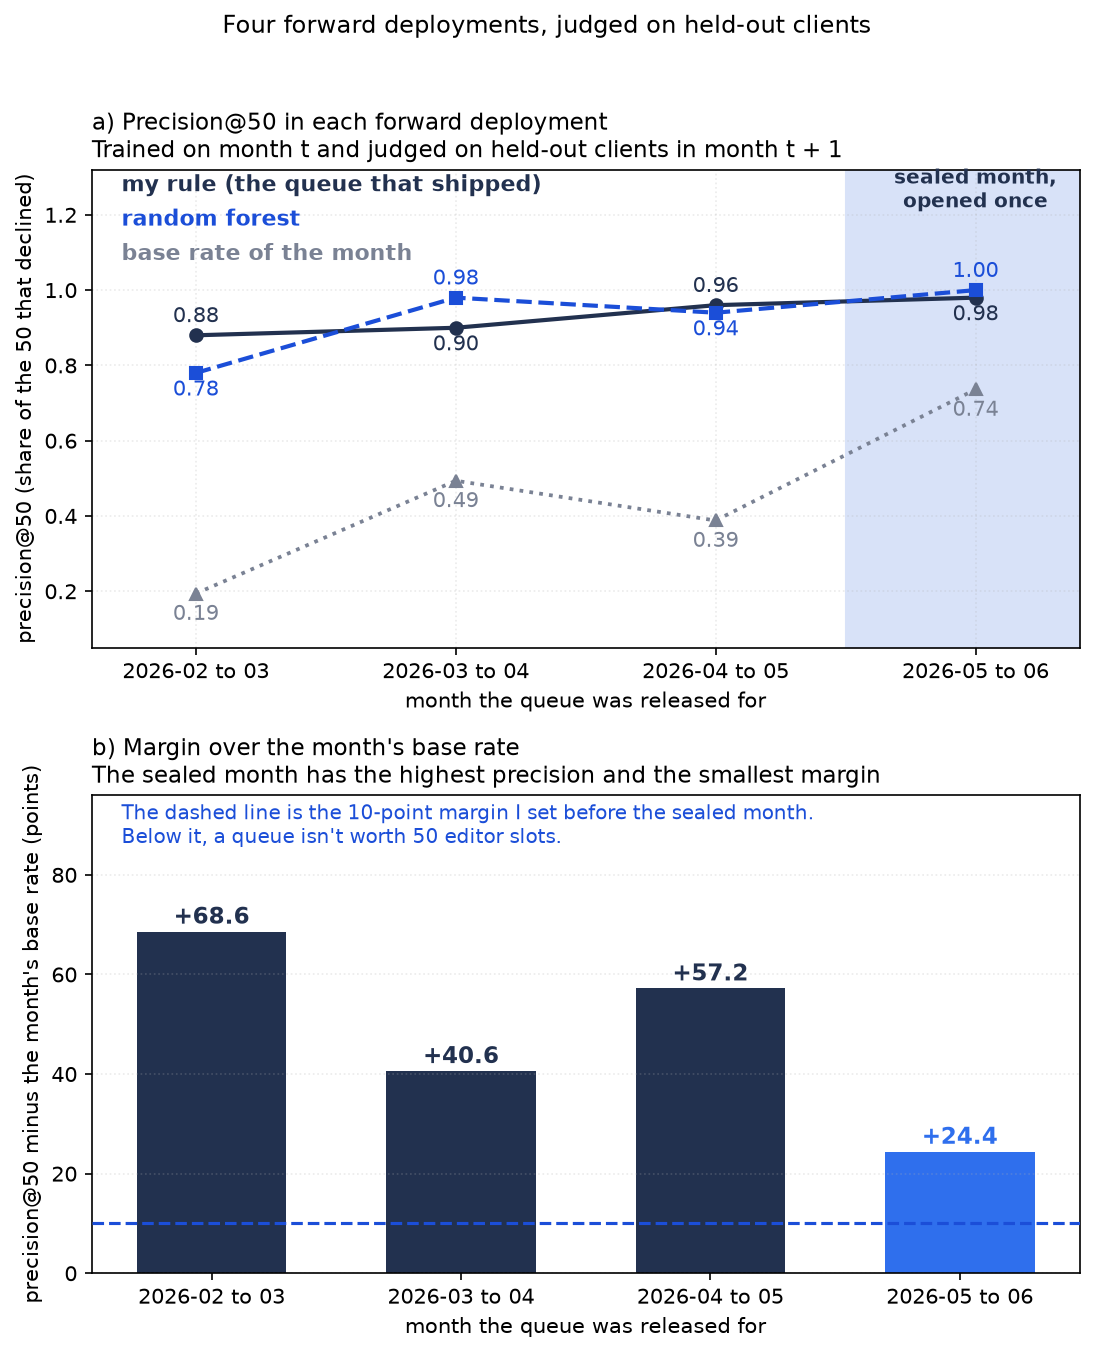

In [4]:
Image(filename=FIGURES / "figure_1_deployments.png")

In [5]:
columns = [
    "clients",
    "pages",
    "base_rate",
    "rule_precision_at_50",
    "forest_precision_at_50",
    "margin_points",
    "rule_auc",
    "forest_auc",
]
pd.DataFrame(results["deployments"]).set_index("deployment")[columns]

,clients,pages,base_rate,rule_precision_at_50,forest_precision_at_50,margin_points,rule_auc,forest_auc
deployment,,,,,,,,
anchor 2026-03 to 2026-04,9,25771,0.4936,0.90,0.90,40.6,0.6270,0.6532
forward 2026-02 to 2026-03,8,21256,0.1940,0.88,0.78,68.6,0.5647,0.5807
forward 2026-03 to 2026-04,9,25771,0.4936,0.90,0.98,40.6,0.6271,0.6723
forward 2026-04 to 2026-05,9,25595,0.3880,0.96,0.94,57.2,0.7150,0.7162
sealed 2026-05 to 2026-06,8,26554,0.7362,0.98,1.00,24.4,0.6330,0.6926


The sealed month gave the highest precision in the project. The rule put 49 declining pages in the first 50. The forest put 50. Those are also the least impressive numbers. The base rate that month was 73.6%. Fifty random pages would hold about 37 declines.

The margin over the base rate can be compared from month to month. It fell from 68.6 points in February to 24.4 in the sealed month while precision rose.

The forest's AUC is above the rule's in all four forward months. It orders the whole list a little better. That doesn't turn into more declining pages in the first 50.

In the sealed month the rule's 50 pages went on to lose 634,253 impressions. The forest's 50 lost 150,432. The rule multiplies by page size on purpose. The forest puts little weight on size.

## The sealed month against simpler rules

In [6]:
pd.DataFrame(results["sealed_comparison"]).set_index("scorer")[
    ["precision_at_50", "auc", "impressions_lost_by_its_50", "median_page_size"]
]

,precision_at_50,auc,impressions_lost_by_its_50,median_page_size
scorer,,,,
rule,0.980,0.6330,634253.0,9700.0
forest,1.000,0.6926,150432.0,1594.0
steepest_slide,0.940,0.6875,43690.0,218.0
lowest_ctr,0.820,0.5739,11286.0,205.0
biggest_pages,0.560,0.4938,1356260.0,110032.0
ctr_fix_flag,0.640,0.5259,1522521.0,101733.0
random_50,0.736,0.5000,NaN,NaN


The rule, the forest and "steepest slide first" all beat the base rate. They also beat the 95th percentile of 200 random queues. That percentile is 0.84. "Biggest pages first" (0.56) and the CTR-fix flag (0.64) fall below the base rate. They answer a different question. They find where there are clicks to win.

"Biggest pages first" puts 1,356,260 lost impressions in front of the editor. That's more than twice the rule's. It's also wrong on 22 of its 50 pages.

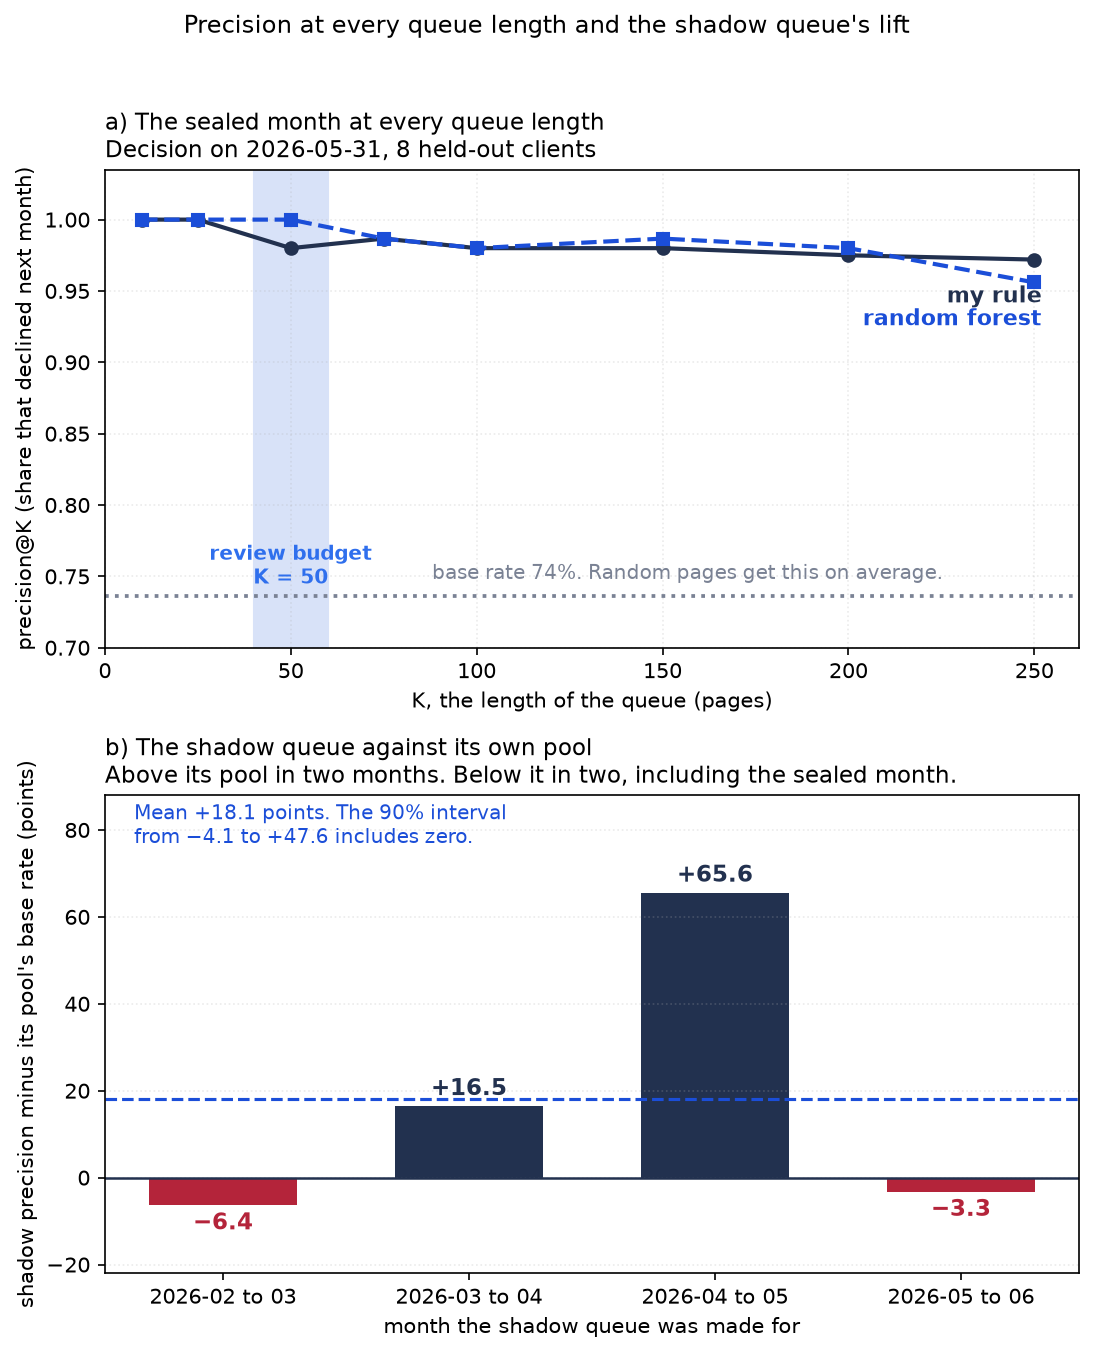

In [7]:
Image(filename=FIGURES / "figure_2_queue_length.png")

The answer doesn't hang on 50 slots. From K = 10 to 250 both stay between 0.956 and 1.000. The rule's margin stays between 23.6 and 26.4 points.

A queue with five pages per held-out client is a harder job. The rule falls from 0.98 to 0.825 and the forest to 0.775. That queue holds 40 pages from 8 clients.

## Intervals

In [8]:
u = results["uncertainty"]
pd.Series(
    {
        "rule, sealed month, 49 of 50": u["sealed_rule_wilson_90"],
        "forest, sealed month, 50 of 50": u["sealed_forest_wilson_90"],
        "forest minus rule, points": u["forest_minus_rule_interval_90"],
        "shadow lift, points": u["shadow_lift_interval_90"],
    },
    name="90% interval",
).to_frame()

,90% interval
"rule, sealed month, 49 of 50","[0.9152, 0.9955]"
"forest, sealed month, 50 of 50","[0.9487, 1.0]"
"forest minus rule, points","[-6.0, 5.0]"
"shadow lift, points","[-4.1, 47.6]"


The base rate sits below both Wilson intervals. Neither interval separates the rule from the forest.

Across the four forward deployments, the forest minus the rule runs −10, +8, −2 and +2 points. The mean is −0.5. The 90% bootstrap interval runs from −6.0 to +5.0 and includes zero. The bootstrap resamples only four numbers. I read it as rough.

## Alarms and decisions

In [9]:
pd.DataFrame(results["alarms"]).set_index("release")

,A1_population_moved,A2_features_drifted,A3_base_rate_moved,A4_queue_below_margin,A5_shadow_lift_not_positive,A6_trial_costs_precision,base_rate_move_points,queue_margin_points
release,,,,,,,,
2026-02 to 2026-03,False,False,False,False,True,True,-4.2,68.6
2026-03 to 2026-04,True,False,True,False,False,True,30.0,40.6
2026-04 to 2026-05,False,False,True,False,False,False,-10.6,57.2
2026-05 to 2026-06,False,False,True,False,True,True,34.8,24.4


I wrote six alarms and two decision rules down before I opened the sealed month.

- A3 fired in the sealed month. The base rate moved 34.8 points. Comparing precision across that move says more about the month than the queue.
- A5 fired. The shadow queue did 3.3 points worse than its own pool. That's the second time in four months. The two aren't in a row. The shadow queue stays open.
- A6 fired for the third time in four months. Ten forest slots would have scored 0.92 against 0.98. The trial isn't promoted.
- A4 never fired. The queue cleared its base rate by more than 10 points every month.
- A1 and A2 stayed quiet on the sealed release. They catch shifts in the inputs. A base rate only shows once the labels arrive.

In [10]:
pd.Series(results["decisions"], name="decided").to_frame()

,decided
close_shadow_queue,False
promote_trial,False
